In [1]:
import torch
import os
import logging
import timm
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import StepLR
from src.dataset import FundusDataset, get_transform, get_soft_balanced_sampler
from src.loss import FocalLoss
from src.model import EfficientNetB4_CBAM, Siamese_EfficientNetB4_CBAM
from src.optimizer import optimizer
from src.trainingfromscratch import training
def seed(seed):
    import random
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed(seed):
    import random
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed(9)

g = torch.Generator()
g.manual_seed(9)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data_dir = "D:/DeepLearning/Dataset/China-Fundus-CIMT"
img_dir = os.path.join(data_dir, "Fundus_CIMT_2903_Dataset")
json_dir = os.path.join(data_dir, "data_info.json")
eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT"
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
log_dir = os.path.join(eval_dir, "logs")

train_transform, valid_transform = get_transform(380)

train_dataset = FundusDataset.from_json(json_dir=json_dir, img_dir=img_dir, group_value=1, transform=train_transform)
valid_dataset = FundusDataset.from_json(json_dir=json_dir, img_dir=img_dir, group_value=2,transform=valid_transform)

sampler, class_weights = get_soft_balanced_sampler(train_dataset, softness=0) # softness=0 means perfect class balance

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    sampler=sampler,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
backbone = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.3)

def kaiming_init(m):
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        if getattr(m, "weight", None) is not None: nn.init.ones_(m.weight)
        if getattr(m, "bias", None) is not None: nn.init.zeros_(m.bias)
        if getattr(m, "running_mean", None) is not None: m.running_mean.zero_()
        if getattr(m, "running_var", None) is not None: m.running_var.fill_(1.0)

backbone.cbam.apply(kaiming_init)

model = Siamese_EfficientNetB4_CBAM(backbone=backbone, classifier_dropout_rate1=0.5, classifier_dropout_rate2=0.5, num_class=2)
model = model.to(device)

alpha_raw = torch.tensor([class_weights[i] for i in sorted(class_weights.keys())], dtype=torch.float)
alpha_smooth = torch.sqrt(alpha_raw)
alpha_tensor = alpha_smooth / alpha_smooth.mean() # normalise with mean so that tensor's average is 1
alpha_tensor = alpha_tensor.to(device)
criterion = FocalLoss(alpha=alpha_tensor, gamma=2)

for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)

log_file = os.path.join(log_dir, 'training_log.txt')
logging.basicConfig(
    filename=log_file,
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    filemode='a'  # use 'a' to append to existing logs
)

best_checkpoint_path = os.path.join(chkpt_dir, "best_checkpoint.pth")
training_record = {
        "train_loss": [],
        "valid_loss": [],
        "train_f1": [],
        "valid_f1": [],
    }

classifier_optimizer = optimizer(model=model, lr=1e-4, weight_decay=1e-4)
scheduler = StepLR(optimizer=classifier_optimizer, step_size=5, gamma=0.5)

training_record = training(model, train_loader, valid_loader, criterion, classifier_optimizer, scheduler, device, chkpt_dir, training_record, num_epochs=20, best_validation_f1=-1.0, start_epoch=0)

checkpoint = torch.load(best_checkpoint_path)
model.load_state_dict(checkpoint["model_state"])
best_validation_f1 = checkpoint["best_valid_f1"]
updated_optimizer = optimizer(model=model, lr=5e-5, weight_decay=1e-4)
scheduler = StepLR(optimizer=updated_optimizer, step_size=5, gamma=0.5)

training_record = training(model, train_loader, valid_loader, criterion, updated_optimizer, scheduler, device, chkpt_dir, training_record, num_epochs=30, best_validation_f1=best_validation_f1, start_epoch=20)

Training: Epoch 1/20:   0%|          | 0/163 [00:00<?, ?it/s]

Validation::   0%|          | 0/13 [00:00<?, ?it/s]

Epoch 1/20:
Train Loss: 0.1626, Train Accuracy: 0.5279, Train F1: 0.4119
Valid Loss: 0.1484, Valid Accuracy: 0.7000, Valid F1: 0.6900
best model saved to:  D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT\checkpointspaper\epoch1_validF1_0.6900.pth


Training: Epoch 2/20:   0%|          | 0/163 [00:00<?, ?it/s]

Validation::   0%|          | 0/13 [00:00<?, ?it/s]

Epoch 2/20:
Train Loss: 0.1486, Train Accuracy: 0.6585, Train F1: 0.6463
Valid Loss: 0.1338, Valid Accuracy: 0.7550, Valid F1: 0.7548
best model saved to:  D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT\checkpointspaper\epoch2_validF1_0.7548.pth


... (80 outputs left out)

Epoch 29/30:
Train Loss: 0.1271, Train Accuracy: 0.7388, Train F1: 0.7340
Valid Loss: 0.1395, Valid Accuracy: 0.7500, Valid F1: 0.7450


Training: Epoch 30/30:   0%|          | 0/163 [00:00<?, ?it/s]

Validation::   0%|          | 0/13 [00:00<?, ?it/s]

Epoch 30/30:
Train Loss: 0.1263, Train Accuracy: 0.7407, Train F1: 0.7382
Valid Loss: 0.1388, Valid Accuracy: 0.7450, Valid F1: 0.7403


{'Normal': {'precision': 0.782608695652174, 'recall': 0.72, 'f1-score': 0.75, 'support': 50.0}, 'Thickened': {'precision': 0.7407407407407407, 'recall': 0.8, 'f1-score': 0.7692307692307693, 'support': 50.0}, 'accuracy': 0.76, 'macro avg': {'precision': 0.7616747181964574, 'recall': 0.76, 'f1-score': 0.7596153846153846, 'support': 100.0}, 'weighted avg': {'precision': 0.7616747181964573, 'recall': 0.76, 'f1-score': 0.7596153846153847, 'support': 100.0}}


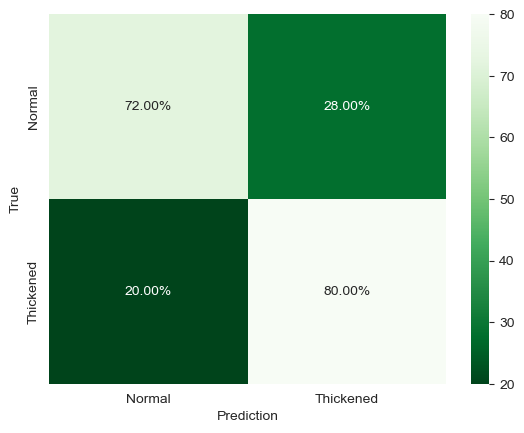

AU-ROC: 0.8404
AU-PRC: 0.8036


In [5]:
import torch
import timm
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score, auc
from src.dataset import FundusDataset, get_transform
from src.model import EfficientNetB4_CBAM, Siamese_EfficientNetB4_CBAM

def seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed(3)

g = torch.Generator()
g.manual_seed(3)

data_dir = "D:/DeepLearning/Dataset/China-Fundus-CIMT"
img_dir = os.path.join(data_dir, "Fundus_CIMT_2903_Dataset")
eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT"
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
result_dir = os.path.join(eval_dir, "results")
json_dir = os.path.join(data_dir, "data_info.json")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transform, valid_transform = get_transform(380)

valid_dataset = FundusDataset.from_json(json_dir=json_dir, img_dir=img_dir, group_value=3, transform=valid_transform)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=40,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
backbone = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.3)
model = Siamese_EfficientNetB4_CBAM(backbone=backbone, classifier_dropout_rate1=0.5, classifier_dropout_rate2=0, num_class=2)
model = model.to(device)
checkpoint = torch.load(os.path.join(chkpt_dir, "epoch21_validF1_0.7692.pth"))
model.load_state_dict(checkpoint["model_state"])

model.eval()
total_valid_loss = 0.0
valid_corrects = 0
all_valid_preds = []
all_valid_labels = []
all_valid_probs = []

with torch.no_grad():
            for i, (left_images, right_images, labels) in enumerate(valid_loader):
                left_images = left_images.to(device, non_blocking=True)
                right_images = right_images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                outputs = model(left_images, right_images)
                _, preds = torch.max(outputs, dim=1)
                valid_corrects += torch.sum(preds == labels.data)
                all_valid_preds.extend(preds.cpu().numpy())
                all_valid_labels.extend(labels.cpu().numpy())
                probs = torch.softmax(outputs, dim=1) # (B,2)
                pos_scores = probs[:, 1] # probability of positive class (class index 1)
                all_valid_probs.extend(pos_scores.cpu().numpy())

class_names = ['Normal', 'Thickened']
report = classification_report(all_valid_labels, all_valid_preds, target_names=class_names, output_dict=True)
print(report)
# report_df = pd.DataFrame(report).transpose()
# report_df.to_csv(os.path.join(result_dir, "report_unfreezing1_test.csv"))

cm = confusion_matrix(all_valid_labels, all_valid_preds)
cm_percentage = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100
labels = np.array([[f"{value:.2f}%" for value in row] for row in cm_percentage])
sns.heatmap(cm_percentage, annot=labels, fmt="", cmap="Greens_r", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediction")
plt.ylabel("True")
# plt.savefig(os.path.join(result_dir, "confusion_matrix_unfreezing1_test.png"), dpi=300)
plt.show()

# AU-ROC and AU-PRC computation
y_true = np.array(all_valid_labels)
y_scores = np.array(all_valid_probs)

unique_classes = np.unique(y_true)
auroc = roc_auc_score(y_true, y_scores)
auprc = average_precision_score(y_true, y_scores)  # average precision == area under PR curve (AP)

print(f"AU-ROC: {auroc:.4f}")
print(f"AU-PRC: {auprc:.4f}")

AU-ROC: 0.8468
AU-PRC: 0.7942
Best threshold by macro-F1 sweep: 0.5118 (macro-F1=0.8300)


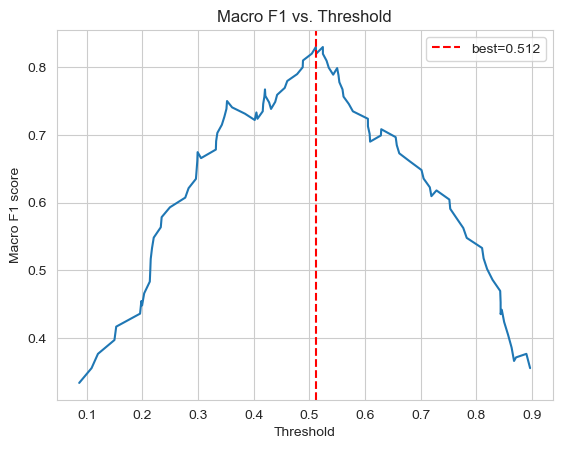

Classification report at threshold=0.5118
{'Normal': {'precision': 0.8235294117647058, 'recall': 0.84, 'f1-score': 0.8316831683168316, 'support': 50.0}, 'Thickened': {'precision': 0.8367346938775511, 'recall': 0.82, 'f1-score': 0.8282828282828283, 'support': 50.0}, 'accuracy': 0.83, 'macro avg': {'precision': 0.8301320528211285, 'recall': 0.83, 'f1-score': 0.8299829982998299, 'support': 100.0}, 'weighted avg': {'precision': 0.8301320528211283, 'recall': 0.83, 'f1-score': 0.82998299829983, 'support': 100.0}}


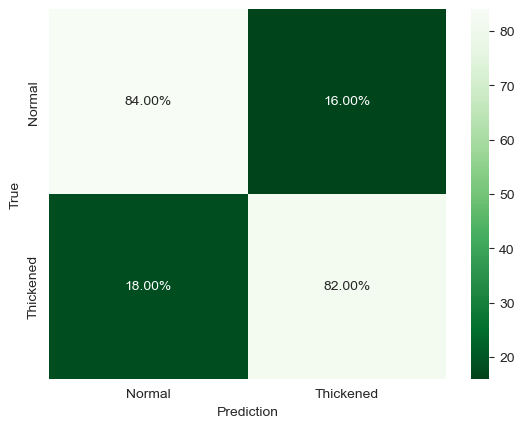

In [7]:
import torch
import timm
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score, f1_score
from src.dataset import FundusDataset, get_transform
from src.model import EfficientNetB4_CBAM, Siamese_EfficientNetB4_CBAM

def seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed(3)

g = torch.Generator()
g.manual_seed(3)

data_dir = "D:/DeepLearning/Dataset/China-Fundus-CIMT"
img_dir = os.path.join(data_dir, "Fundus_CIMT_2903_Dataset")
eval_dir = "D:/DeepLearning/Evaluation/EfficientNet-B4/China-Fundus-CIMT"
chkpt_dir = os.path.join(eval_dir, "checkpointspaper")
result_dir = os.path.join(eval_dir, "results")
json_dir = os.path.join(data_dir, "data_info.json")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transform, valid_transform = get_transform(380)

valid_dataset = FundusDataset.from_json(json_dir=json_dir, img_dir=img_dir, group_value=3, transform=valid_transform)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=40,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    prefetch_factor=2,
    generator=g,
)

base_model = timm.create_model("efficientnet_b4", pretrained=True, features_only=False)
backbone = EfficientNetB4_CBAM(model=base_model, cbam_dropout_rate=0.3)
model = Siamese_EfficientNetB4_CBAM(backbone=backbone, classifier_dropout_rate1=0.5, classifier_dropout_rate2=0, num_class=2)
model = model.to(device)
checkpoint = torch.load(os.path.join(chkpt_dir, "epoch14_validF1_0.7899.pth"))
model.load_state_dict(checkpoint["model_state"])

model.eval()
all_valid_labels = []
all_valid_probs = []

with torch.no_grad():
    for i, (left_images, right_images, labels) in enumerate(valid_loader):
        left_images = left_images.to(device, non_blocking=True)
        right_images = right_images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(left_images, right_images)
        probs = torch.softmax(outputs, dim=1)  # (B,2)
        pos_scores = probs[:, 1]  # probability of positive class (class index 1)
        all_valid_labels.extend(labels.cpu().numpy())
        all_valid_probs.extend(pos_scores.cpu().numpy())

y_true = np.array(all_valid_labels)
y_scores = np.array(all_valid_probs)
class_names = ['Normal', 'Thickened']

# AU-ROC / AU-PRC (threshold-independent)
auroc = roc_auc_score(y_true, y_scores)
auprc = average_precision_score(y_true, y_scores)
print(f"AU-ROC: {auroc:.4f}")
print(f"AU-PRC: {auprc:.4f}")

# --- Find threshold that maximizes macro F1 ---
candidate_thresholds = np.unique(y_scores)
macro_f1_scores = np.array([
    f1_score(y_true, (y_scores >= t).astype(int), average='macro')
    for t in candidate_thresholds
])
best_idx = np.argmax(macro_f1_scores)
best_threshold = candidate_thresholds[best_idx]
print(f"Best threshold by macro-F1 sweep: {best_threshold:.4f} (macro-F1={macro_f1_scores[best_idx]:.4f})")

plt.figure()
plt.plot(candidate_thresholds, macro_f1_scores)
plt.axvline(best_threshold, color='r', linestyle='--', label=f'best={best_threshold:.3f}')
plt.xlabel("Threshold")
plt.ylabel("Macro F1 score")
plt.title("Macro F1 vs. Threshold")
plt.legend()
plt.show()

# --- Recompute metrics at best threshold ---
all_valid_preds = (y_scores >= best_threshold).astype(int)

report = classification_report(y_true, all_valid_preds, target_names=class_names, output_dict=True)
print(f"Classification report at threshold={best_threshold:.4f}")
print(report)
# report_df = pd.DataFrame(report).transpose()
# report_df.to_csv(os.path.join(result_dir, "report_unfreezing1_test.csv"))

cm = confusion_matrix(y_true, all_valid_preds)
cm_percentage = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100
labels = np.array([[f"{value:.2f}%" for value in row] for row in cm_percentage])
sns.heatmap(cm_percentage, annot=labels, fmt="", cmap="Greens_r", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediction")
plt.ylabel("True")
# plt.savefig(os.path.join(result_dir, "confusion_matrix_unfreezing1_test.png"), dpi=300)
plt.show()